In [30]:
# python libraries imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# customed local functions imports
import sys
sys.path.append("./scripts")

from utils import *

#### **Dataset load and details**

In [2]:
ratings = load_ml100k()
print("============ MovieLens 100k Dataset ===========")
print(f"#Ratings: {ratings["rating"].count()} | #Users: {ratings['user'].nunique()} | #Items: {ratings['item'].nunique()} ")

============ MovieLens 100k Dataset ===========
#Ratings: 100000 | #Users: 943 | #Items: 1682 


In [3]:
ratings["rating"].describe()

count    100000.000000
mean          0.705972
std           0.225135
min           0.200000
25%           0.600000
50%           0.800000
75%           0.800000
max           1.000000
Name: rating, dtype: float64

**Effectiveness**

In [5]:
results = []

distances = ["l1", "l2"]
aggregates = ["avg", "max", "min"]

# Compute once, it doesn't depend on the variant
aa = average_ranking(ratings)

for distance in distances:
    for aggregate in aggregates:
        rep = reputation_ranking(ratings, distance, aggregate)
        tau = kendall(rep, aa)

        results.append({
            "algorithm": f"{distance.upper()}-{aggregate.upper()}",
            "kendall_tau": tau,
        })

df_clean = pd.DataFrame(results)
display(df_clean)

,algorithm,kendall_tau
0,L1-AVG,0.995186
1,L1-MAX,0.989826
2,L1-MIN,0.995939
3,L2-AVG,0.995438
4,L2-MAX,0.992436
5,L2-MIN,0.996566


**Robustness**

In [3]:
results = []

distances = ["l1", "l2"]
aggregates = ["avg", "max", "min"]
spam_ratios = [0.1, 0.3, 0.5]

# Noisy datasets: generated once per ratio, shared by all algorithms
noisy_datasets = {p: add_spammers(ratings, p) for p in spam_ratios}

# Baseline (AA): original vs noisy
aa_orig = average_ranking(ratings)
for p, noisy in noisy_datasets.items():
    results.append({
        "algorithm": "AA",
        "spam_ratio": p,
        "kendall_tau": kendall(aa_orig, average_ranking(noisy)),
    })

# Reputation-based algorithms: original vs noisy
for distance in distances:
    for aggregate in aggregates:
        rep_orig = reputation_ranking(ratings, distance, aggregate)

        for p, noisy in noisy_datasets.items():
            rep_noisy = reputation_ranking(noisy, distance, aggregate)

            results.append({
                "algorithm": f"{distance.upper()}-{aggregate.upper()}",
                "spam_ratio": p,
                "kendall_tau": kendall(rep_orig, rep_noisy),
            })

df_robust = pd.DataFrame(results)

# Table: one row per algorithm, one column per spam ratio
display(df_robust.pivot(index="algorithm", columns="spam_ratio", values="kendall_tau"))

spam_ratio,0.1,0.3,0.5
algorithm,,,
AA,0.701042,0.604888,0.580052
L1-AVG,0.702032,0.606548,0.581844
L1-MAX,0.702533,0.606175,0.580958
L1-MIN,0.701181,0.607332,0.583345
L2-AVG,0.700320,0.604330,0.579937
L2-MAX,0.700319,0.603965,0.579096
L2-MIN,0.699007,0.603642,0.579403


#### **Bribery**
the seller of most-rated item sequentially bribes the first 100 users who rated the item with a rating below the maximum allowed to change the rating to the maximum one. Then, the profit after bribing each user is computed

In [32]:
clean_ranking = reputation_ranking(ratings, distance="l1", aggregate="avg")

results = []
for n in range(0, 101, 20):
    bribed_ratings, bribe_item = bribe(ratings, r_max=1, num_bribe_users=n)
    bribed_ranking = reputation_ranking(bribed_ratings, distance="l1", aggregate="avg")

    result = compute_profit(ratings, bribed_ratings, clean_ranking, bribed_ranking, bribe_item)
    result["num_bribe_users"] = n
    results.append(result)

results = pd.DataFrame(results).set_index("num_bribe_users")
pd.options.display.float_format = "{:.4f}".format   # show 4 decimals
print(results)

                 J_before  J_after    cost  profit  profitable
num_bribe_users                                               
0                508.2614 508.2614  0.0000  0.0000       False
20               508.2614 508.2573  6.4000 -0.0041       False
40               508.2614 508.2562 11.8000 -0.0052       False
60               508.2614 508.2432 17.8000 -0.0182       False
80               508.2614 508.2309 24.0000 -0.0305       False
100              508.2614 508.2216 30.8000 -0.0398       False


                algorithm  J_before  J_after    cost  profit
num_bribe_users                                             
0                      AA  508.2000 508.2000  0.0000  0.0000
0                  L1-AVG  508.2614 508.2614  0.0000  0.0000
20                     AA  508.2000 508.2000  6.4000  0.0000
20                 L1-AVG  508.2614 508.2573  6.4000 -0.0041
40                     AA  508.2000 508.2000 11.8000  0.0000
40                 L1-AVG  508.2614 508.2562 11.8000 -0.0052
60                     AA  508.2000 508.2000 17.8000  0.0000
60                 L1-AVG  508.2614 508.2432 17.8000 -0.0182
80                     AA  508.2000 508.2000 24.0000  0.0000
80                 L1-AVG  508.2614 508.2309 24.0000 -0.0305
100                    AA  508.2000 508.2000 30.8000  0.0000
100                L1-AVG  508.2614 508.2216 30.8000 -0.0398


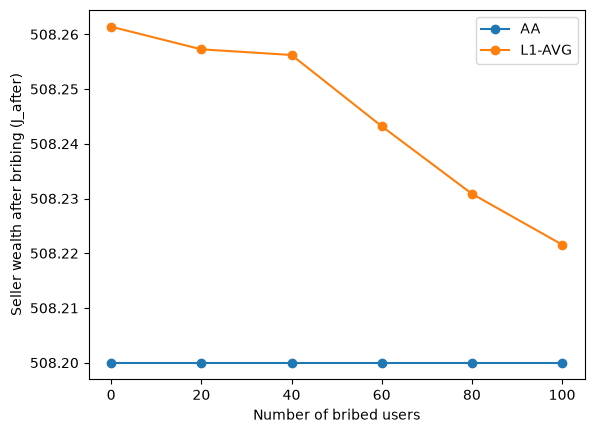

In [39]:
results = []

aa_clean = average_ranking(ratings)
rep_clean = reputation_ranking(ratings, "l1", "avg")

for n in range(0, 101, 20):
    bribed_ratings, bribe_item = bribe(ratings, r_max=1, num_bribe_users=n)

    aa_bribed = average_ranking(bribed_ratings)
    rep_bribed = reputation_ranking(bribed_ratings, "l1", "avg")

    aa_result = compute_profit(ratings, bribed_ratings, aa_clean, aa_bribed, bribe_item)
    rep_result = compute_profit(ratings, bribed_ratings, rep_clean, rep_bribed, bribe_item)

    aa_result["algorithm"] = "AA"
    aa_result["num_bribe_users"] = n
    rep_result["algorithm"] = "L1-AVG"
    rep_result["num_bribe_users"] = n

    results.append(aa_result)
    results.append(rep_result)

df_bribe = pd.DataFrame(results)
df_bribe = df_bribe[["num_bribe_users", "algorithm", "J_before", "J_after", "cost", "profit"]] # set columns order

pd.options.display.float_format = "{:.4f}".format   # show 4 decimals
print(df_bribe.set_index("num_bribe_users"))

for algorithm, group in df_bribe.groupby("algorithm"):
    plt.plot(group["num_bribe_users"], group["J_after"], marker="o", label=algorithm)

plt.xlabel("Number of bribed users")
plt.ylabel("Seller wealth after bribing (J_after)")
plt.legend()
plt.show()